# Réseaux convolutionnels pour le traitement de l'image

## Partie E : Architectures U-Net — que se passe-t-il dans la représentation ?

Vincent Guigue (vincent.guigue@agroparistech.fr)

Dans les TP précédents, le CNN *résume* l'image : à force de convolutions et de pooling, on obtient un vecteur qui dit **quoi** (la classe), mais on a perdu **où**. Pour la **segmentation** (une classe par pixel), il faut les deux à la fois. L'architecture U-Net ([Ronneberger et al., 2015](https://arxiv.org/abs/1505.04597)) résout cette tension avec :
- un **encodeur** qui descend en résolution (comme un CNN classique) jusqu'à un **goulot** (*bottleneck*) ;
- un **décodeur** symétrique qui remonte en résolution ;
- des **connexions de saut** (*skip connections*) qui recopient les cartes de l'encodeur vers le décodeur, niveau par niveau.

### Objectif pédagogique

Comprendre **quelle information circule par quel chemin**. L'hypothèse que nous allons tester expérimentalement :

> les skips transportent le **« où »** (contours, position précise), le goulot transporte le **« quoi »** (contexte, identité de l'objet).

### Budget

Tout tient sur un portable : données générées à partir de MNIST (déjà téléchargé dans les TP précédents), images 64×64, réseaux d'environ 100k paramètres, quelques minutes d'apprentissage par modèle. Des poids pré-entraînés sont fournis dans `models/` pour ceux qui veulent sauter les apprentissages.

### Plan
- **A.** Construire un U-Net (mini-exos sur les tailles, puis le réseau)
- **B.** Une tâche qui demande le « quoi » ET le « où » : segmenter des chiffres MNIST sur un canevas — comparaison de 3 architectures
- **C.** Introspection de la représentation : ablations, images chimères, sondes linéaires, champ réceptif, géométrie des représentations
- **D.** Ouverture : le rôle du goulot dépend de la tâche (identité vs reconstruction de zones masquées)

In [3]:
from tqdm.auto import tqdm
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
from contextlib import contextmanager
import time
import os

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import OneCycleLR

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("device :", device)
torch.manual_seed(0)

device : cuda


In [4]:
from pathlib import Path
TB_PATH = str(Path("./logs/module2").absolute())
try:
    from torch.utils.tensorboard import SummaryWriter
    print(f"Pour visualiser les logs : tensorboard --logdir {Path(TB_PATH).absolute()}")
except ImportError: # tensorboard absent : on continue sans
    class SummaryWriter:
        def __init__(self, *args, **kwargs): pass
        def add_scalar(self, *args, **kwargs): pass
        def close(self): pass
    print("tensorboard non installé : les courbes ne seront pas enregistrées (les métriques sont affichées à chaque epoch)")

Pour visualiser les logs : tensorboard --logdir c:\cours_code\Python\DeepLearning_vguigue\2-Convolution\notebooks\logs\module2


# Partie A : Construire un U-Net

```
 entrée 1x64x64
    │ enc0 (2 conv 3x3)
 8x64x64 ───────────────────────── skip0 ─────────────────────────► concat ─► dec0 ─► 8x64x64 ─► conv 1x1 ─► 11x64x64
    │ pool                                                            ▲ up
    │ enc1                                                            │
 16x32x32 ──────────────── skip1 ────────────────► concat ─► dec1 ─► 16x32x32
    │ pool                                            ▲ up
    │ enc2                                            │
 32x16x16 ─────── skip2 ───────► concat ─► dec2 ─► 32x16x16
    │ pool                          ▲ up
    │ goulot                        │
 64x8x8 ────────────────────────────┘
```

Les opérations nouvelles par rapport aux TP précédents :
- [`ConvTranspose2d`](https://pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html) : convolution « inverse », qui **augmente** la résolution (avec `kernel_size=2, stride=2`, elle double la taille) ;
- `torch.cat([a, b], dim=1)` : concaténation selon l'axe des canaux (c'est ainsi qu'on branche un skip) ;
- `Conv2d(..., kernel_size=1)` : une couche linéaire appliquée pixel par pixel (la « tête » de classification).

## A.1 Mini-exos sur les tailles

Prédire les tailles des `y` suivants **sans exécuter le code !!** Puis vérifier.

In [5]:
# Batch x nfilter x width x height
x = torch.randn(4, 8, 64, 64)

y1 = nn.Conv2d(8, 16, kernel_size=3, padding=1)(x)
y2 = nn.MaxPool2d(2)(x)
y3 = nn.ConvTranspose2d(8, 4, kernel_size=2, stride=2)(x)
y4 = nn.Upsample(scale_factor=2, mode="nearest")(x)
y5 = torch.cat([x, x], dim=1)
y6 = nn.Conv2d(8, 11, kernel_size=1)(x)

# Questions complémentaires :
# Q1. Combien de paramètres dans nn.ConvTranspose2d(8, 4, kernel_size=2, stride=2) ? Et dans nn.Upsample ?
# Q2. Une image MNIST 28x28 passe dans 3 MaxPool2d(2) successifs, puis 3 ConvTranspose2d(k=2, s=2).
#     Quelle taille obtient-on ? Peut-on concaténer avec les skips ? Pourquoi travaille-t-on en 64x64 ?

##  TODO 

## A.2 Le réseau

Le bloc de base est une double convolution 3×3 (avec BatchNorm). On vous la donne.

Compléter la classe `UNet` :
- le décodeur : pour chaque niveau (du plus profond au plus haut), une `ConvTranspose2d` qui double la résolution en divisant les canaux par 2, puis une `DoubleConv` qui prend en entrée **la concaténation** de la sortie de l'up et du skip ;
- la méthode `forward`.

**Points d'accroche.** On ajoute des modules `nn.Identity()` (`skip_tap[i]` et `bottleneck_tap`) qui ne changent rien au calcul : ils servent uniquement à poser des *hooks* (cf. TP 2_4) pour **lire** ou **remplacer** le contenu des skips et du goulot. Attention : `skip_tap[i]` ne doit agir que sur la branche skip, pas sur la branche qui descend vers le niveau suivant.

**Option `skips=False`.** Les skips sont remplacés par des zéros : même architecture, même nombre de paramètres, mais on a « coupé les câbles ». C'est un auto-encodeur convolutionnel classique.

In [22]:
# en mode héritage (on aurait pu faire une variante en utilisant Sequantial autrement)
class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU())


class UNet(nn.Module):
    def __init__(self, in_ch=1, n_classes=11, base=8, depth=3, skips=True, name="unet"):
        super().__init__()
        self.name, self.depth, self.skips = name, depth, skips
        chs = [base * 2**i for i in range(depth + 1)]       # depth=3, base=8 => [8, 16, 32, 64]
        # encodeur
        self.enc = nn.ModuleList()
        cin = in_ch
        for c in chs[:-1]:
            self.enc.append(DoubleConv(cin, c))
            cin = c
        self.pool = nn.MaxPool2d(2)
        # goulot
        self.bottleneck = DoubleConv(chs[-2], chs[-1])
        # décodeur : self.up[k] et self.dec[k], k=0 correspondant au niveau le plus profond
        self.up = nn.ModuleList([nn.ConvTranspose2d(chs[i + 1], chs[i], 2, stride=2) for i in reversed(range(depth))])
        self.dec = nn.ModuleList([DoubleConv(2 * chs[i], chs[i]) for i in reversed(range(depth))])
        self.head = nn.Conv2d(chs[0], n_classes, 1)
        # points d'accroche pour les hooks (ne modifient pas le calcul)
        # hook = plus facile de récupérer les valeurs
        self.skip_tap = nn.ModuleList([nn.Identity() for _ in range(depth)])
        self.bottleneck_tap = nn.Identity()

    def forward(self, x):
        skips = []      # sorties de l'encodeur, à réutiliser dans le décodeur
        for i, encoder in enumerate(self.enc):
            x = encoder(x)
            skips.append(self.skip_tap[i](x))   # le tap n'agit que sur la branche skip
            x = self.pool(x)
        x = self.bottleneck_tap(self.bottleneck(x))
        for up, dec, s in zip(self.up, self.dec, reversed(skips)):
            x = up(x)
            if not self.skips:
                s = torch.zeros_like(s)
            x = dec(torch.cat([x, s], dim=1))
        return self.head(x)


def n_params(model):
    return sum(p.numel() for p in model.parameters())

net = UNet()
print(net(torch.randn(2, 1, 64, 64)).shape)   # attendu : (2, 11, 64, 64)
print(f"{n_params(net)} paramètres")

torch.Size([2, 11, 64, 64])
121123 paramètres


# Partie B : Une tâche qui demande le « quoi » et le « où »

## B.1 Les données : des chiffres MNIST sur un canevas

On colle 1 à 3 chiffres MNIST à des positions aléatoires sur un canevas noir de 64×64. La vérité terrain est une carte de **11 classes** par pixel : 0 = fond, $d+1$ = pixel appartenant au chiffre $d$.

- Pas d'annotation à faire : le masque s'obtient en seuillant le chiffre.
- Pour bien segmenter, le réseau doit **reconnaître** le chiffre (il faut voir le chiffre en entier : contexte large) et **délimiter** ses pixels au pixel près (information locale, haute résolution).

In [23]:
import torchvision.datasets as dset

root = '/tmp/'
mnist_train = dset.MNIST(root=root, train=True, download=True)
mnist_test = dset.MNIST(root=root, train=False, download=True)
# accès direct aux tenseurs uint8 (N, 28, 28) : pas besoin de transforms ici
digits_train, labels_train = mnist_train.data, mnist_train.targets
digits_test, labels_test = mnist_test.data, mnist_test.targets

SIZE = 64   # taille du canevas

def make_canvas(imgs, labels, positions, size=SIZE):
    """Colle des chiffres MNIST (uint8, 28x28) sur un canevas noir.
    Renvoie x (image uint8), y (classe par pixel : 0 = fond, d+1 = chiffre d)
    et inst (numéro d'instance par pixel : 0 = fond, k+1 = k-ième chiffre collé)."""
    x = torch.zeros(size, size, dtype=torch.uint8)
    y = torch.zeros(size, size, dtype=torch.uint8)
    inst = torch.zeros(size, size, dtype=torch.uint8)
    for k, (img, lab, (i, j)) in enumerate(zip(imgs, labels, positions)):
        x[i:i+28, j:j+28] = torch.maximum(x[i:i+28, j:j+28], img)
        mask = img > 127
        y[i:i+28, j:j+28][mask] = lab + 1
        inst[i:i+28, j:j+28][mask] = k + 1
    return x, y, inst

def random_positions(n, gen, size=SIZE, overlap=6):
    """Tire (au plus) n coins haut-gauche tels que les boîtes 28x28 se chevauchent d'au plus `overlap` pixels."""
    pos = []
    for _ in range(200):
        i, j = torch.randint(0, size - 28 + 1, (2,), generator=gen).tolist()
        if all(abs(i - a) >= 28 - overlap or abs(j - b) >= 28 - overlap for a, b in pos):
            pos.append((i, j))
            if len(pos) == n:
                break
    return pos

class SegMNIST(Dataset):
    def __init__(self, digits, labels, n, max_digits=3, seed=0):
        gen = torch.Generator().manual_seed(seed)
        self.X = torch.zeros(n, 1, SIZE, SIZE, dtype=torch.uint8)  # stockage compact en uint8
        self.Y = torch.zeros(n, SIZE, SIZE, dtype=torch.uint8)
        self.present = torch.zeros(n, 10)                           # chiffres présents (pour la partie C)
        for t in range(n):
            k = torch.randint(1, max_digits + 1, (1,), generator=gen).item()
            pos = random_positions(k, gen)
            idx = torch.randint(0, len(digits), (len(pos),), generator=gen)
            x, y, _ = make_canvas(digits[idx], labels[idx], pos)
            self.X[t, 0], self.Y[t] = x, y
            self.present[t, labels[idx]] = 1

    def __len__(self):
        return len(self.X)

    def __getitem__(self, t):
        return self.X[t].float() / 255, self.Y[t].long()

t0 = time.time()
seg_train = SegMNIST(digits_train, labels_train, 10000, seed=0)
seg_test = SegMNIST(digits_test, labels_test, 1000, seed=1)
print(f"données générées en {time.time() - t0:.1f}s")

BATCH = 64
train_loader = DataLoader(seg_train, batch_size=BATCH, shuffle=True)
test_loader = DataLoader(seg_test, batch_size=256, shuffle=False)

données générées en 6.5s


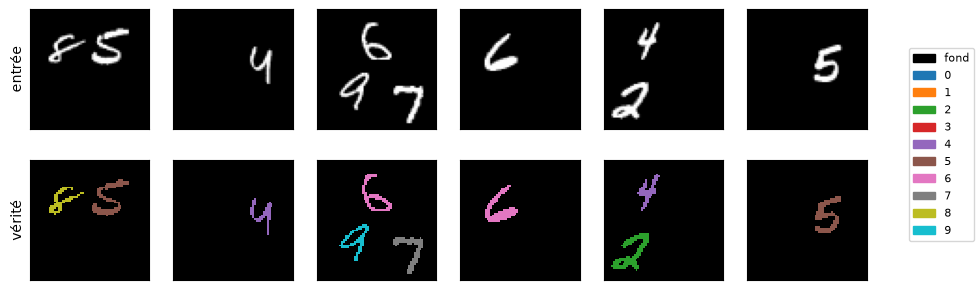

In [24]:
CMAP = ListedColormap(["black"] + [plt.cm.tab10(i) for i in range(10)])
LEGEND = [Patch(color=CMAP(0), label="fond")] + [Patch(color=CMAP(d + 1), label=str(d)) for d in range(10)]

def show_batch(x, maps, titles, n=6):
    """x : batch d'entrées (B,1,H,W) ; maps : liste de cartes (B,H,W) de classes ; titles : nom de chaque ligne."""
    fig, axs = plt.subplots(1 + len(maps), n, figsize=(1.8 * n, 1.8 * (1 + len(maps))), squeeze=False)
    for j in range(n):
        axs[0, j].imshow(x[j, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
        for r, m in enumerate(maps):
            axs[r + 1, j].imshow(m[j].detach().cpu(), cmap=CMAP, vmin=0, vmax=10, interpolation="nearest")
    for r, t in enumerate(["entrée"] + titles):
        axs[r, 0].set_ylabel(t)
    for a in axs.flat:
        a.set_xticks([]); a.set_yticks([])
    fig.legend(handles=LEGEND, loc="center right", fontsize=8)
    plt.subplots_adjust(right=0.9)
    plt.show()

xb, yb = next(iter(test_loader))
show_batch(xb, [yb], ["vérité"])

## B.2 Métriques : séparer le « où » du « quoi »

L'accuracy par pixel est trompeuse (le fond représente environ 90 % des pixels : prédire « fond » partout donne déjà 90 %). On sépare deux questions :
- **`iou_fg`** (« où ») : en ignorant les classes, le réseau trouve-t-il les bons pixels ? IoU entre l'ensemble des pixels prédits « chiffre » (classe > 0) et l'ensemble des vrais pixels « chiffre ».
- **`acc_cls`** (« quoi ») : parmi les pixels qui sont des chiffres **et** prédits comme chiffres, quelle proportion reçoit la bonne classe ?

Compléter `seg_counts`, qui renvoie les comptages permettant de calculer ces deux métriques sur un batch (on les cumule ensuite sur tout le jeu de test).

In [37]:
def seg_counts(logits, y):
    """logits : (B,11,H,W), y : (B,H,W). Renvoie (intersection, union, nb_bien_classés, nb_pixels_fg_trouvés)."""
    ypred = logits.argmax(1)
    yt, ypredt = y>0, ypred>0
    both = yt & ypredt
    inter = both.sum()
    union = (yt | ypredt).sum()
    correct = ((ypred==y) & both).sum()
    return inter.item(), union.item(), correct.item(), both.sum().item()

Pour les ablations de la partie C, on aura besoin de **modifier** le contenu d'un point d'accroche pendant le forward. Un *forward hook* qui **renvoie** une valeur remplace la sortie du module. Le gestionnaire de contexte `edited` pose les hooks puis les retire proprement :
```python
with edited(model, {"bottleneck": lambda o: torch.zeros_like(o)}):
    out = model(x)     # forward avec un goulot remis à zéro
```

In [35]:
def taps(model):
    """Dictionnaire nom -> point d'accroche."""
    d = {f"skip{i}": m for i, m in enumerate(model.skip_tap)}
    d["bottleneck"] = model.bottleneck_tap
    return d

@contextmanager
def edited(model, edits):
    """edits : dict nom_du_point_d_accroche -> fonction(tenseur) -> tenseur de remplacement."""
    handles = [taps(model)[k].register_forward_hook(lambda m, inp, out, f=f: f(out)) for k, f in edits.items()]
    try:
        yield model
    finally:
        for h in handles:
            h.remove()

@torch.no_grad()
def evaluate_seg(model, loader, edits={}):
    model.eval().to(device)
    I = U = C = B = 0
    with edited(model, edits):
        for x, y in loader:
            i, u, c, b = seg_counts(model(x.to(device)), y.to(device))
            I, U, C, B = I + i, U + u, C + c, B + b
    return {"iou_fg": I / max(U, 1), "acc_cls": C / max(B, 1)}

## B.3 Apprentissage de trois architectures

| modèle | description | hypothèse |
|---|---|---|
| `unet` | U-Net profondeur 3, avec skips | |
| `noskip` | même réseau, skips coupés (auto-encodeur) | ? |
| `shallow` | U-Net profondeur 1, même largeur | ? |

Les trois modèles utilisent `base=16` (16 canaux au premier niveau).

**Avant de lancer** : pour `noskip` et `shallow`, formuler une hypothèse sur `iou_fg` et `acc_cls`. Calculer (à la main !) le champ réceptif théorique d'un pixel du goulot pour la profondeur 1 et la profondeur 3. Rappel : en notant $r$ la taille du champ réceptif et $j$ le pas cumulé (en pixels de l'entrée), une couche de noyau $k$ et de pas $s$ fait $r \leftarrow r + (k-1)\,j$ puis $j \leftarrow j\,s$.

In [ ]:
    ##  TODO 

In [38]:
def train(model, epochs, train_loader, test_loader, loss_fn=nn.CrossEntropyLoss(), evaluate=evaluate_seg, max_lr=3e-3):
    writer = SummaryWriter(f"{TB_PATH}/{model.name}")
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr)
    scheduler = OneCycleLR(optimizer, max_lr=max_lr, steps_per_epoch=len(train_loader), epochs=epochs)
    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        cumloss, count = 0., 0
        for x, y in tqdm(train_loader, desc=f"{model.name} {epoch + 1}/{epochs}", leave=False):
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            l = loss_fn(model(x), y)
            l.backward()
            optimizer.step()
            scheduler.step()
            cumloss += l.item() * len(x)
            count += len(x)
        writer.add_scalar("loss/train", cumloss / count, epoch)
        msg = f"[{model.name}] epoch {epoch + 1} ({time.time() - t0:.0f}s) loss {cumloss / count:.4f}"
        for k, v in evaluate(model, test_loader).items():
            writer.add_scalar(f"{k}/test", v, epoch)
            msg += f" | {k} {v:.3f}"
        print(msg)
    writer.close()
    return model

def save_model(model, fichier):
    torch.save({'model_state': model.state_dict()}, fichier)

def load_model(fichier, model):
    if os.path.isfile(fichier):
        model.load_state_dict(torch.load(fichier, map_location="cpu")['model_state'])
    else:
        print(f"Erreur de chargement de {fichier} :\n => ATTENTION : initialisation aléatoire")
    return model.to(device)

In [40]:
TRAIN = True     # False : on charge les modèles fournis dans models/
EPOCHS = 4       # environ 2 min/epoch sur CPU (M1), beaucoup moins sur GPU/MPS
os.makedirs("models", exist_ok=True)

BASE = 16
unet = UNet(base=BASE, name="unet")
noskip = UNet(base=BASE, skips=False, name="noskip")
shallow = UNet(base=BASE, depth=1, name="shallow")
for m in [unet, noskip, shallow]:
    print(f"{m.name:8s} {n_params(m):7d} paramètres")

for m in [unet, noskip, shallow]:
    fichier = f"models/unet25_{m.name}.pt"
    if TRAIN:
        train(m, EPOCHS, train_loader, test_loader)
        save_model(m, fichier)
    else:
        load_model(fichier, m)

unet      482619 paramètres
noskip    482619 paramètres
shallow    25691 paramètres


unet 1/4:   0%|          | 0/157 [00:00<?, ?it/s]

[unet] epoch 1 (6s) loss 1.2387 | iou_fg 0.923 | acc_cls 0.142


unet 2/4:   0%|          | 0/157 [00:00<?, ?it/s]

[unet] epoch 2 (13s) loss 0.1464 | iou_fg 0.960 | acc_cls 0.243


unet 3/4:   0%|          | 0/157 [00:00<?, ?it/s]

... (15 outputs left out)

shallow 3/4:   0%|          | 0/157 [00:00<?, ?it/s]

[shallow] epoch 3 (16s) loss 0.1209 | iou_fg 0.735 | acc_cls 0.148


shallow 4/4:   0%|          | 0/157 [00:00<?, ?it/s]

[shallow] epoch 4 (21s) loss 0.1164 | iou_fg 0.747 | acc_cls 0.150


## B.4 Comparaison

Comparer les performances des 3 architectures en test + utiliser `show_batch` pour avoir un résultat qualitatif

modèle      iou_fg  acc_cls
unet         0.959    0.683
noskip       0.526    0.763
shallow      0.747    0.150


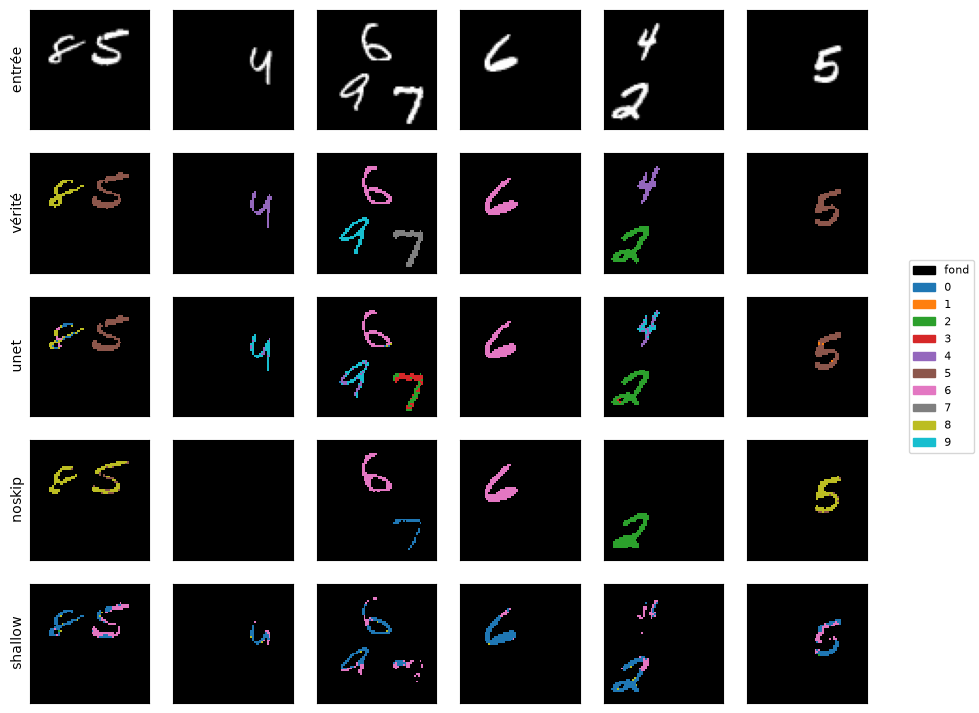

In [41]:
models = {"unet": unet, "noskip": noskip, "shallow": shallow}
print(f"{'modèle':10s} {'iou_fg':>7s} {'acc_cls':>8s}")
for name, m in models.items():
    r = evaluate_seg(m, test_loader)
    print(f"{name:10s} {r['iou_fg']:7.3f} {r['acc_cls']:8.3f}")

with torch.no_grad():
    preds = [m.eval()(xb.to(device)).argmax(1) for m in models.values()]
show_batch(xb, [yb] + preds, ["vérité"] + list(models))

**Question.** Les résultats confirment-ils vos hypothèses ? Décrire le type d'erreur de chaque modèle (regarder les images, pas seulement les chiffres).

In [31]:
##  TODO 

# Partie C : Que contient la représentation ?

On travaille maintenant sur le `unet` entraîné. Les outils : les points d'accroche et les hooks.

## C.0 Un premier regard

Compléter `capture`, qui renvoie un dictionnaire `nom -> tenseur` contenant le contenu de tous les points d'accroche pour une entrée `x` (indice : utiliser `edited` avec des fonctions qui stockent leur argument et le renvoient inchangé).

skip0 (1, 16, 64, 64)
skip1 (1, 32, 32, 32)
skip2 (1, 64, 16, 16)
bottleneck (1, 128, 8, 8)


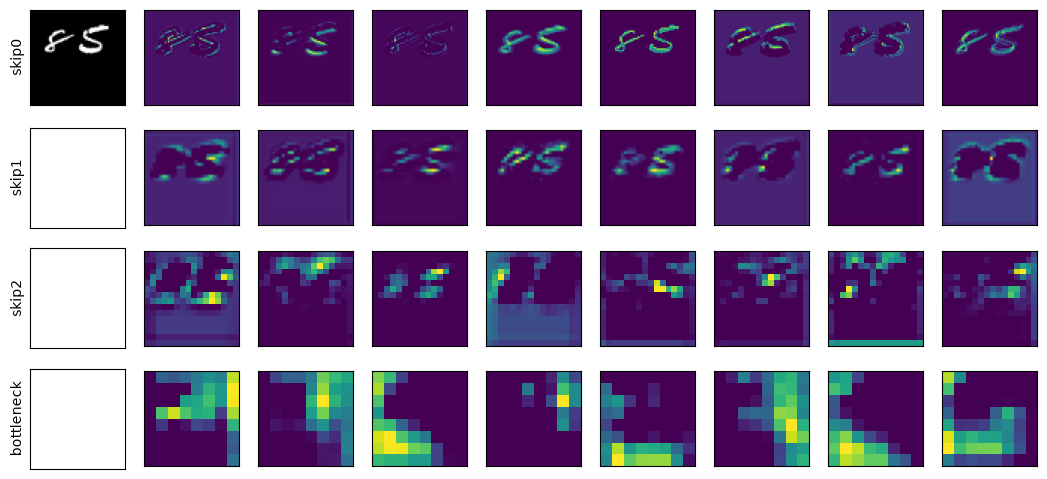

In [43]:
# la correction est donnée... Mais il faut comprendre ce qui est fait
@torch.no_grad()
def capture(model, x):
    model.eval()
    store = {}
    def keep(name):
        def f(o):
            store[name] = o.detach()
            return o
        return f
    with edited(model, {k: keep(k) for k in taps(model)}):
        model(x.to(device))
    return store

acts = capture(unet, xb[:1])
for k, v in acts.items():
    print(k, tuple(v.shape))

fig, axs = plt.subplots(4, 9, figsize=(13, 6))
axs[0, 0].imshow(xb[0, 0], cmap="gray")
for r, k in enumerate(["skip0", "skip1", "skip2", "bottleneck"]):
    axs[r, 0].set_ylabel(k)
    for c in range(8):
        axs[r, c + 1].imshow(acts[k][0, c].cpu(), cmap="viridis")
for a in axs.flat:
    a.set_xticks([]); a.set_yticks([])
plt.show()

**Question.** Que semblent coder les canaux de `skip0` ? Ceux du goulot sont-ils interprétables à l'œil ? (c'est le même constat que dans le TP 2_2 : plus on descend, moins c'est lisible… d'où les expériences quantitatives suivantes).

## C.1 Ablations

On remplace le contenu d'un point d'accroche et on mesure l'effet sur `iou_fg` (« où ») et `acc_cls` (« quoi »).

**Point de méthode.** Remplacer par **zéro** est brutal : le décodeur reçoit des valeurs qu'il n'a jamais vues (les statistiques de BatchNorm s'effondrent) et on mesure autant la « surprise » du réseau que la perte d'information. Remplacer par la **moyenne** (calculée sur des images de test) supprime l'information propre à l'image tout en gardant des valeurs plausibles. On compare les deux.

Construire le tableau d'ablation pour : aucune modification, goulot → moyenne, goulot → 0, chaque skip → moyenne, tous les skips → moyenne.

ablation                  iou_fg  acc_cls
aucune                     0.959    0.683
goulot -> moyenne          0.938    0.401
goulot -> 0                0.944    0.424
skip0 -> moyenne           0.000    1.000
skip1 -> moyenne           0.953    0.273
skip2 -> moyenne           0.946    0.395
skip2 -> 0                 0.955    0.299
tous skips -> moyenne      0.000    0.000


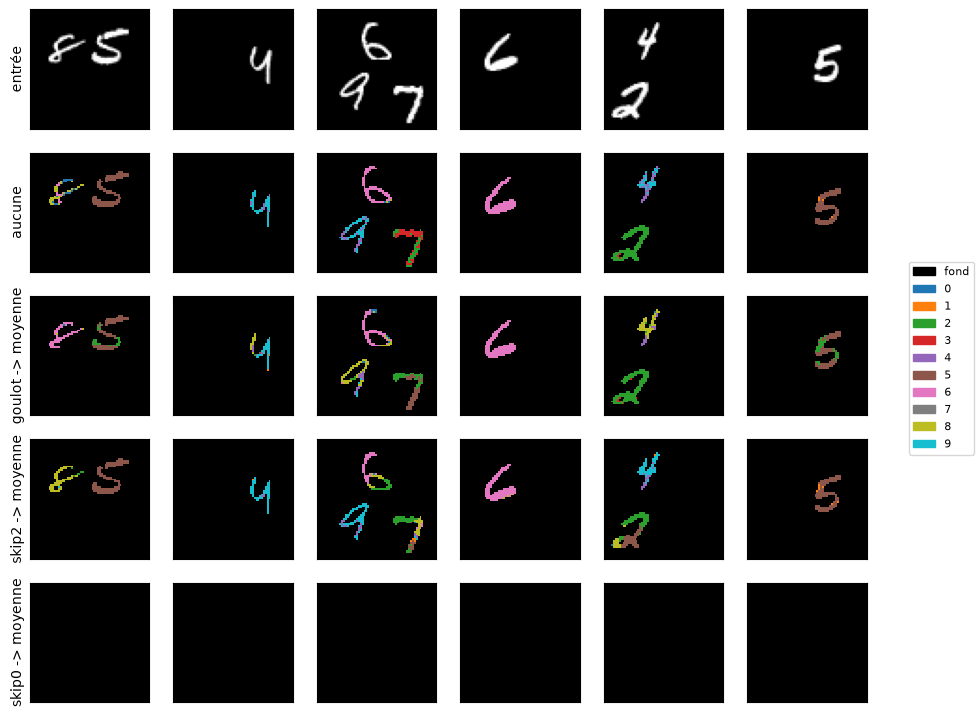

In [ ]:
def replace_by(t):
    return lambda o: t.expand_as(o)

xm, _ = next(iter(DataLoader(seg_test, batch_size=512)))
means = {k: v.mean(0, keepdim=True) for k, v in capture(unet, xm).items()}

conditions = {
    "aucune": {},
    "goulot -> moyenne": {"bottleneck": replace_by(means["bottleneck"])},
    "goulot -> 0": {"bottleneck": torch.zeros_like},
    "skip0 -> moyenne": {"skip0": replace_by(means["skip0"])},
    "skip1 -> moyenne": {"skip1": replace_by(means["skip1"])},
    "skip2 -> moyenne": {"skip2": replace_by(means["skip2"])},
    "skip2 -> 0": {"skip2": torch.zeros_like},
    "tous skips -> moyenne": {f"skip{i}": replace_by(means[f"skip{i}"]) for i in range(3)},
}
print(f"{'ablation':24s} {'iou_fg':>7s} {'acc_cls':>8s}")
for name, ed in conditions.items():
    r = evaluate_seg(unet, test_loader, ed)
    print(f"{name:24s} {r['iou_fg']:7.3f} {r['acc_cls']:8.3f}")

with torch.no_grad():
    shown = ["aucune", "goulot -> moyenne", "skip2 -> moyenne", "skip0 -> moyenne"]
    preds = []
    for name in shown:
        with edited(unet, conditions[name]):
            preds.append(unet(xb.to(device)).argmax(1))
show_batch(xb, preds, shown)

**Question.** Quel chemin porte le « où » ? le « quoi » ? L'hypothèse de départ (« skips = où, goulot = quoi ») est-elle confirmée ? Comparer aussi les ablations par zéro et par la moyenne.

In [45]:
##  TODO 

## C.2 Images chimères

Expérience plus directe : on fabrique des **paires** d'images (A, B) avec **les mêmes positions** mais **des chiffres différents**. On fait passer B dans le réseau, mais on remplace certains points d'accroche par leur contenu calculé sur A.

Si les points d'accroche remplacés portent le « quoi » et ceux de B le « où », la prédiction doit avoir **les formes de B** et **les classes de A**.

Pour le mesurer : sur les pixels de B correctement détectés comme chiffres, on compte la proportion de pixels étiquetés avec la classe de B, avec la classe de A (du chiffre situé au même endroit), ou autre chose.

Écrire `chimera(model, xA, xB, from_A)` (`from_A` : liste des points d'accroche pris dans A) et tester : goulot seul ; skip2 seul ; skip2 + goulot ; skip1 + skip2 + goulot.

pris dans A               détectés  classe B  classe A   autre
goulot                       95.2%     18.3%     30.3%   51.4%
skip2                        95.2%     39.8%     12.2%   48.0%
skip2 + goulot               96.1%      6.1%     58.8%   35.1%
skip1 + skip2 + goulot       96.4%      6.8%     45.2%   48.0%


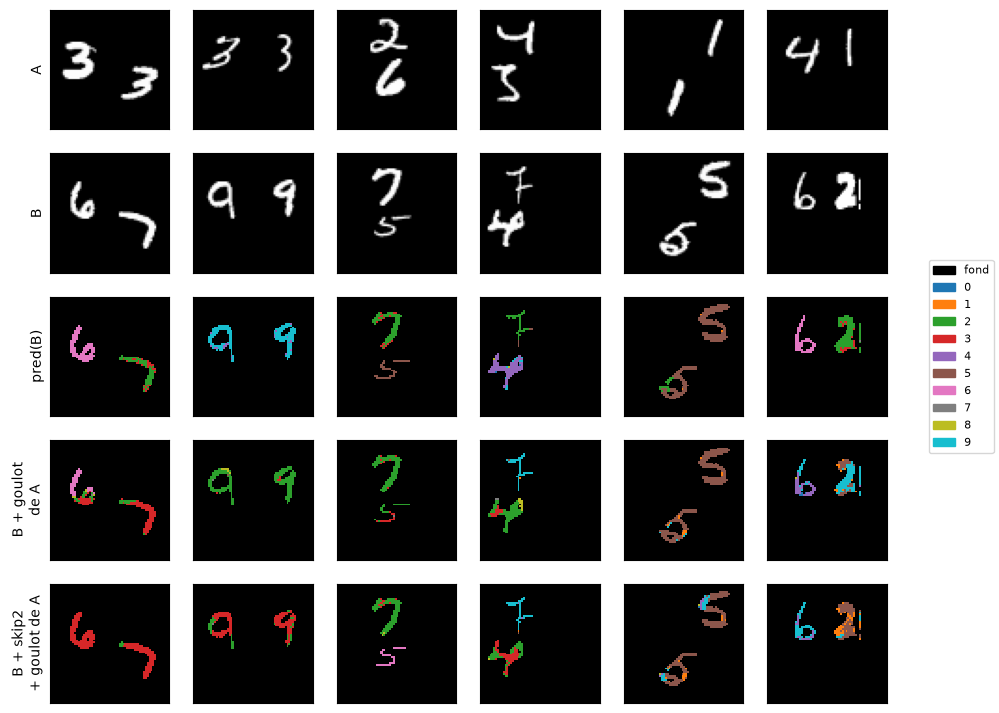

In [46]:
def make_pairs(n, digits, labels, n_digits=2, seed=3):
    gen = torch.Generator().manual_seed(seed)
    XA, XB, YB, YAonB = [], [], [], []
    while len(XA) < n:
        pos = random_positions(n_digits, gen)
        iA = torch.randint(0, len(digits), (len(pos),), generator=gen)
        iB = torch.randint(0, len(digits), (len(pos),), generator=gen)
        if (labels[iA] == labels[iB]).any():      # on veut des chiffres différents à chaque position
            continue
        xA, _, _ = make_canvas(digits[iA], labels[iA], pos)
        xB, yB, instB = make_canvas(digits[iB], labels[iB], pos)
        lut = torch.cat([torch.zeros(1, dtype=torch.long), labels[iA] + 1])   # instance de B -> classe de A
        XA.append(xA); XB.append(xB); YB.append(yB.long()); YAonB.append(lut[instB.long()])
    f = lambda L: torch.stack(L)
    return f(XA)[:, None].float() / 255, f(XB)[:, None].float() / 255, f(YB), f(YAonB)

xA, xB, yB, yAonB = make_pairs(500, digits_test, labels_test)


def chimera(model, xA, xB, from_A):
    acts_A = capture(model, xA)
    with torch.no_grad(), edited(model, {k: (lambda o, t=acts_A[k]: t) for k in from_A}):
        return model(xB.to(device)).argmax(1).cpu()

swaps = {"goulot": ["bottleneck"],
         "skip2": ["skip2"],
         "skip2 + goulot": ["skip2", "bottleneck"],
         "skip1 + skip2 + goulot": ["skip1", "skip2", "bottleneck"]}
print(f"{'pris dans A':24s} {'détectés':>9s} {'classe B':>9s} {'classe A':>9s} {'autre':>7s}")
chims = {}
for name, from_A in swaps.items():
    p = chims[name] = chimera(unet, xA, xB, from_A)
    det = (yB > 0) & (p > 0)
    cB, cA = (p == yB)[det].float().mean(), (p == yAonB)[det].float().mean()
    print(f"{name:24s} {det.sum() / (yB > 0).sum():9.1%} {cB:9.1%} {cA:9.1%} {1 - cA - cB:7.1%}")

with torch.no_grad():
    pred_B = unet(xB.to(device)).argmax(1).cpu()
n = 6
fig, axs = plt.subplots(5, n, figsize=(1.8 * n, 9))
rows = [(xA, "gray", "A"), (xB, "gray", "B"), (pred_B, CMAP, "pred(B)"),
        (chims["goulot"], CMAP, "B + goulot\nde A"), (chims["skip2 + goulot"], CMAP, "B + skip2\n+ goulot de A")]
for r, (data, cmap, title) in enumerate(rows):
    for j in range(n):
        img = data[j, 0] if data.dim() == 4 else data[j]
        axs[r, j].imshow(img, cmap=cmap, **({} if cmap == "gray" else dict(vmin=0, vmax=10, interpolation="nearest")))
        axs[r, j].set_xticks([]); axs[r, j].set_yticks([])
    axs[r, 0].set_ylabel(title)
fig.legend(handles=LEGEND, loc="center right", fontsize=8)
plt.subplots_adjust(right=0.9)
plt.show()


**Questions.**
1. Interpréter les proportions obtenues.
2. Avec la meilleure combinaison, que se passe-t-il si A et B n'ont **pas** les mêmes positions ? Tester (indice : il suffit de générer A avec un autre `seed`). Qu'est-ce que cela dit de la nature de ces représentations : vecteur global ou carte spatiale ?

In [47]:
##  TODO 

## C.3 Sondes linéaires

Une **sonde** (*probe*) est un classifieur linéaire entraîné sur une représentation **gelée** : si un classifieur linéaire arrive à prédire une information, c'est qu'elle est présente (et facilement lisible) dans la représentation.

Tâche de la sonde : prédire **quels chiffres sont présents** dans l'image (10 sorties binaires) à partir d'un point d'accroche, résumé par un *max-pooling global* (un vecteur de taille = nombre de canaux).

On compare : `skip0`, `skip1`, `skip2`, `bottleneck` du `unet` ; le goulot du `noskip` ; et le goulot d'un U-Net **non entraîné** (initialisation aléatoire) — une baseline indispensable.

Pour vérifier que vous avez compris le principe, tentez de dessiner l'architecture au brouillon

In [48]:
@torch.no_grad()
def pooled_features(model, dataset, tap, n=3000, bs=500):
    feats = []
    for s in range(0, min(n, len(dataset)), bs):
        x = dataset.X[s:s + bs].float() / 255
        feats.append(capture(model, x)[tap].amax(dim=(2, 3)).cpu())   # max-pooling global
    return torch.cat(feats), dataset.present[:min(n, len(dataset))]

def linear_probe(Ftr, Ytr, Fte, Yte, epochs=500):
    mu, sd = Ftr.mean(0), Ftr.std(0) + 1e-6
    Ftr, Fte = (Ftr - mu) / sd, (Fte - mu) / sd
    lin = nn.Linear(Ftr.shape[1], Ytr.shape[1])
    opt = torch.optim.Adam(lin.parameters(), lr=1e-2)
    for _ in range(epochs):
        opt.zero_grad()
        F.binary_cross_entropy_with_logits(lin(Ftr), Ytr).backward()
        opt.step()
    with torch.no_grad():
        p = (lin(Fte) > 0).float()
    tp, fp, fn = (p * Yte).sum(0), (p * (1 - Yte)).sum(0), ((1 - p) * Yte).sum(0)
    return (tp / (tp + 0.5 * (fp + fn) + 1e-9)).mean().item()   # F1 moyen sur les 10 chiffres


random_unet = UNet(base=BASE, name="random").to(device)
candidats = [("unet", unet, "skip0"), ("unet", unet, "skip1"), ("unet", unet, "skip2"),
             ("unet", unet, "bottleneck"), ("noskip", noskip, "bottleneck"), ("aléatoire", random_unet, "bottleneck")]
print(f"{'modèle':10s} {'point':11s} {'dim':>4s} {'F1':>6s}")
for mname, m, tap in candidats:
    Ftr, Ytr = pooled_features(m, seg_train, tap)
    Fte, Yte = pooled_features(m, seg_test, tap, n=1000)
    print(f"{mname:10s} {tap:11s} {Ftr.shape[1]:4d} {linear_probe(Ftr, Ytr, Fte, Yte):6.3f}")


modèle     point        dim     F1
unet       skip0         16  0.151
unet       skip1         32  0.549
unet       skip2         64  0.789
unet       bottleneck   128  0.815
noskip     bottleneck   128  0.754
aléatoire  bottleneck   128  0.426


**Questions.**
1. Où l'information « quels chiffres sont présents » est-elle linéairement lisible ?
2. Comparer les goulots de `unet` et `noskip`. Lequel s'attendait-on à trouver le plus « sémantique » ?
3. Pourquoi la baseline aléatoire est-elle indispensable ? Quelle autre critique peut-on faire à cette comparaison (regarder la colonne `dim`) ?

In [49]:
##  TODO 

**Synthèse.** Pourquoi le réseau n'utilise-t-il (presque) pas son goulot ? Proposer des modifications de la **tâche** ou de **l'entraînement** qui l'obligeraient à s'en servir.

In [50]:
##  TODO 

## C.4 Champ réceptif effectif

Le champ réceptif théorique (calculé en B.3) est une borne : en pratique, l'influence des pixels de l'entrée sur un pixel de sortie décroît vite avec la distance. On mesure le **champ réceptif effectif** comme une carte de saillance (TP 2_2) : le gradient de la sortie au pixel central par rapport à l'entrée, moyenné sur un batch.

Comparer `shallow` et `unet` et superposer le champ réceptif théorique.

NameError: name 'theoretical_rf' is not defined

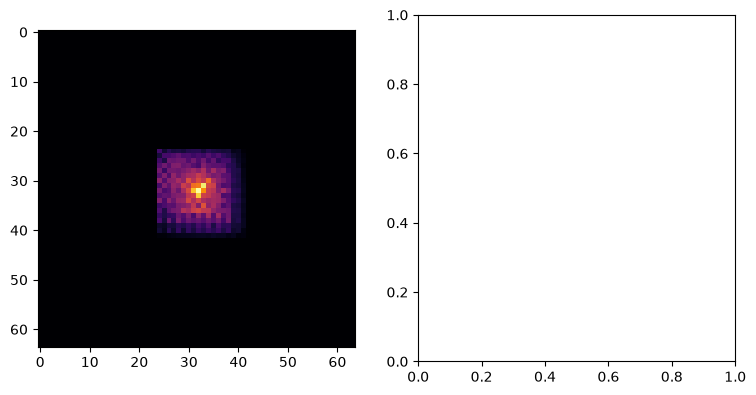

In [51]:
def effective_rf(model, x, i=SIZE // 2, j=SIZE // 2):
    model.eval()
    x = x.clone().to(device).requires_grad_(True)
    out = model(x)
    out[:, :, i, j].max(1).values.sum().backward()   # logit de la classe prédite au pixel (i, j)
    return x.grad.abs().mean(0)[0].cpu()
    


fig, axs = plt.subplots(1, 2, figsize=(9, 4.5))
for a, m in zip(axs, [shallow, unet]):
    g = effective_rf(m, xb[:128])
    a.imshow(g ** 0.5, cmap="inferno")                # racine carrée pour mieux voir les queues
    r = theoretical_rf(m.depth, to_output=True)
    a.add_patch(Rectangle((SIZE // 2 - r / 2, SIZE // 2 - r / 2), r, r, fill=False, color="cyan", lw=2))
    a.set_title(f"{m.name} (théorique {r} px)")
    a.set_xlim(-0.5, SIZE - 0.5); a.set_ylim(SIZE - 0.5, -0.5)
plt.show()


**Question.** Le champ réceptif effectif occupe-t-il tout le champ théorique ? Relier à l'échec de `shallow` en B.4.

In [ ]:
##  TODO 

## C.5 Géométrie des représentations

Chaque position du goulot (grille 8×8) est un vecteur (dimension = nombre de canaux) qui décrit un carré de 8×8 pixels de l'entrée ; chaque position de `skip2` décrit un carré de 4×4 pixels, chaque position de `skip0` un pixel. Ces vecteurs se regroupent-ils par classe de chiffre ?

On projette ces vecteurs en 2D par ACP, en coloriant chaque point par la classe majoritaire (hors fond) de la zone correspondante. On ne garde que les positions qui contiennent des pixels de chiffre.

In [ ]:
def position_vectors(model, tap, n_img=200):
    x, y = seg_test.X[:n_img].float() / 255, seg_test.Y[:n_img].long()
    a = capture(model, x)[tap].cpu()                        # (N, C, h, w)
    k = SIZE // a.shape[-1]                                 # taille de la zone décrite par une position
    onehot = F.one_hot(y, 11).permute(0, 3, 1, 2).float()   # (N, 11, H, W)
    counts = F.avg_pool2d(onehot, k)[:, 1:]                 # proportion de chaque chiffre par zone
    keep = counts.sum(1) > 0.1                              # zones avec au moins 10 % de pixels « chiffre »
    vec = a.permute(0, 2, 3, 1)[keep]                       # (M, C)
    cls = counts.argmax(1)[keep]                            # classe majoritaire (0..9)
    return vec, cls

def pca2(v):
    v = v - v.mean(0)
    _, _, V = torch.pca_lowrank(v, q=2, center=False)
    return v @ V[:, :2]


fig, axs = plt.subplots(1, 3, figsize=(16, 5))
for a, tap in zip(axs, ["skip0", "skip2", "bottleneck"]):
    vec, cls = position_vectors(unet, tap)
    if len(vec) > 4000:
        sel = torch.randperm(len(vec))[:4000]
        vec, cls = vec[sel], cls[sel]
    p = pca2(vec)
    a.scatter(p[:, 0], p[:, 1], c=cls, cmap=ListedColormap([plt.cm.tab10(i) for i in range(10)]),
              vmin=-0.5, vmax=9.5, s=4, alpha=0.6)
    a.set_title(f"{tap} : {vec.shape[1]} dimensions, {len(vec)} positions")
fig.legend(handles=LEGEND[1:], loc="center right", fontsize=8)
plt.show()


**Question.** Que conclure ? Pour aller plus loin : remplacer l'ACP par un t-SNE (`sklearn.manifold.TSNE`), ou entraîner une sonde linéaire *par position* (prédire la classe de la zone à partir du vecteur).

In [ ]:
##  TODO 

# Partie D : Le rôle du goulot dépend de la tâche

Le rôle du goulot dépend-il de l'architecture ou de la **tâche** ? On garde la même architecture (U-Net de profondeur 3, ici en version légère `base=8` ; sortie : 1 canal, perte MSE) et on change seulement la tâche :
- **identité** : reconstruire l'image d'entrée ;
- **reconstruction de zone masquée** (*inpainting*) : un carré de 20×20 pixels est remplacé par du gris (0.5) ; il faut reconstruire l'image complète.

In [ ]:
FILL, HOLE = 0.5, 20

class ReconMNIST(Dataset):
    def __init__(self, base, mode="identity", fixed=False, seed=0):
        self.base, self.mode, self.fixed = base, mode, fixed
        gen = torch.Generator().manual_seed(seed)
        self.pos = torch.randint(0, SIZE - HOLE + 1, (len(base), 2), generator=gen)  # trous fixes (test)

    def __len__(self):
        return len(self.base)

    def __getitem__(self, t):
        x, _ = self.base[t]
        if self.mode == "identity":
            return x, x
        i, j = (self.pos[t] if self.fixed else torch.randint(0, SIZE - HOLE + 1, (2,))).tolist()
        xin = x.clone()
        xin[:, i:i + HOLE, j:j + HOLE] = FILL
        return xin, x

@torch.no_grad()
def evaluate_recon(model, loader, edits={}):
    """MSE dans le trou et hors du trou (pour l'identité : pas de trou, tout est « hors trou »)."""
    model.eval().to(device)
    se_in = se_out = n_in = n_out = 0
    with edited(model, edits):
        for xin, x in loader:
            xin, x = xin.to(device), x.to(device)
            err = (model(xin) - x) ** 2
            hole = xin == FILL          # 0.5 n'est jamais une valeur k/255 de MNIST : pas d'ambiguïté
            se_in += err[hole].sum().item(); n_in += hole.sum().item()
            se_out += err[~hole].sum().item(); n_out += (~hole).sum().item()
    return {"mse_trou": se_in / max(n_in, 1), "mse_hors": se_out / max(n_out, 1)}

recon_loaders = {}
for mode in ["identity", "inpaint"]:
    recon_loaders[mode] = (DataLoader(ReconMNIST(seg_train, mode), batch_size=BATCH, shuffle=True),
                           DataLoader(ReconMNIST(seg_test, mode, fixed=True), batch_size=256))

In [ ]:
# version légère (base=8) : suffisante pour ces tâches de régression, et deux fois plus rapide
ident = UNet(n_classes=1, base=8, name="identity")
inpaint = UNet(n_classes=1, base=8, name="inpaint")
for m, mode, ep in [(ident, "identity", 2), (inpaint, "inpaint", EPOCHS)]:
    fichier = f"models/unet25_{m.name}.pt"
    if TRAIN:
        train(m, ep, *recon_loaders[mode], loss_fn=nn.MSELoss(), evaluate=evaluate_recon, max_lr=3e-3)
        save_model(m, fichier)
    else:
        load_model(fichier, m)

Refaire l'ablation « goulot → moyenne » (et « skip0 → moyenne ») sur les deux modèles. Conclure.

In [ ]:

for m, mode in [(ident, "identity"), (inpaint, "inpaint")]:
    xin_m, _ = next(iter(DataLoader(recon_loaders[mode][1].dataset, batch_size=512)))
    mm = {k: v.mean(0, keepdim=True) for k, v in capture(m, xin_m).items()}
    print(f"--- {m.name}")
    for name, ed in [("aucune", {}), ("goulot -> moyenne", {"bottleneck": replace_by(mm["bottleneck"])}),
                     ("skip0 -> moyenne", {"skip0": replace_by(mm["skip0"])})]:
        r = evaluate_recon(m, recon_loaders[mode][1], ed)
        print(f"{name:20s} " + " | ".join(f"{k} {v:.4f}" for k, v in r.items()))

xin, x = next(iter(recon_loaders["inpaint"][1]))
mm = {k: v.mean(0, keepdim=True) for k, v in capture(inpaint, xin).items()}
with torch.no_grad():
    out = inpaint(xin.to(device)).cpu()
    with edited(inpaint, {"bottleneck": replace_by(mm["bottleneck"])}):
        out_nb = inpaint(xin.to(device)).cpu()
n = 6
fig, axs = plt.subplots(4, n, figsize=(1.8 * n, 7.5))
for r, (data, title) in enumerate([(xin, "entrée"), (x, "cible"), (out, "sortie"), (out_nb, "goulot\n-> moyenne")]):
    for j in range(n):
        axs[r, j].imshow(data[j, 0].clamp(0, 1), cmap="gray", vmin=0, vmax=1)
        axs[r, j].set_xticks([]); axs[r, j].set_yticks([])
    axs[r, 0].set_ylabel(title)
plt.show()


In [ ]:
##  TODO 

## Pour aller plus loin

- **La largeur est aussi un goulot.** Ré-entraîner `unet` avec `base=8` : la dernière couche n'a plus que 8 canaux à pleine résolution pour séparer 11 classes. On observe des chiffres entiers classés en « fond » et un apprentissage très instable : quand le réseau hésite entre plusieurs chiffres, la probabilité du fond l'emporte à l'argmax.
- **Skips à gain appris.** Multiplier chaque skip par un scalaire $\alpha_\ell$ appris, avec une pénalité $\lambda \sum_\ell |\alpha_\ell|$ : quels skips le réseau garde-t-il selon la tâche (segmentation, identité, inpainting) ?
- **Skip dropout.** Couper aléatoirement les skips pendant l'apprentissage force le goulot à porter plus d'information : refaire les sondes de C.3.
- **Lien avec les modèles de diffusion.** Les générateurs d'images actuels (Stable Diffusion, etc.) utilisent un U-Net comme débruiteur : selon le niveau de bruit, l'information utile vient plutôt des skips (peu de bruit : il suffit de nettoyer localement) ou du goulot (beaucoup de bruit : il faut « imaginer » la structure globale). C'est exactement le contraste identité / inpainting de la partie D.

# Construction du sujet à partir de la correction

In [ ]:
###  TODO  ###